# Practical 2A — Uber Fare Prediction using Regression

Clean fare records, calculate trip distance and pickup hour, inspect outliers and correlations, then compare Linear, Ridge and Lasso regression.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create a small synthetic Uber-style fares dataset for this practical.
import numpy as np, pandas as pd
rng = np.random.default_rng(42)
n = 3000
lat1, lon1 = rng.normal(40.75, .03, n), rng.normal(-73.98, .03, n)
lat2, lon2 = lat1 + rng.normal(0, .04, n), lon1 + rng.normal(0, .04, n)
km = np.sqrt(((lat2-lat1)*111)**2 + ((lon2-lon1)*84)**2)
fare = 2.5 + 1.8*km + rng.normal(0, 1.5, n)
fare[rng.choice(n, 25, replace=False)] += rng.uniform(40, 120, 25)
lat1[rng.choice(n, 10, replace=False)] = 0
uber = pd.DataFrame({"pickup_datetime":pd.date_range("2015-01-01", periods=n, freq="3h"),
 "pickup_longitude":lon1, "pickup_latitude":lat1, "dropoff_longitude":lon2,
 "dropoff_latitude":lat2, "passenger_count":rng.integers(1,6,n), "fare_amount":fare.round(2)})
uber.to_csv("data/uber.csv", index=False)
print("Created data/uber.csv", uber.shape)


Created data/uber.csv (3000, 7)


## 3. Practical implementation

The following cells perform the analysis and show the output.

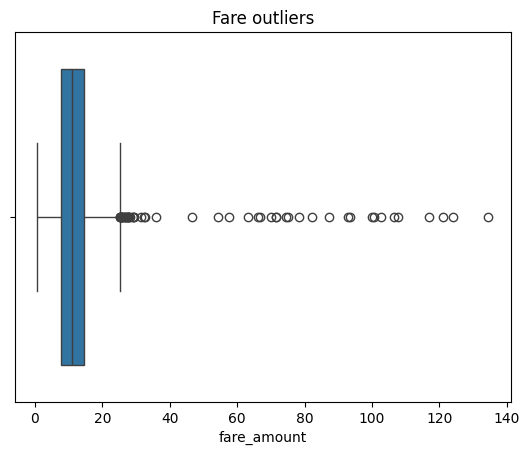

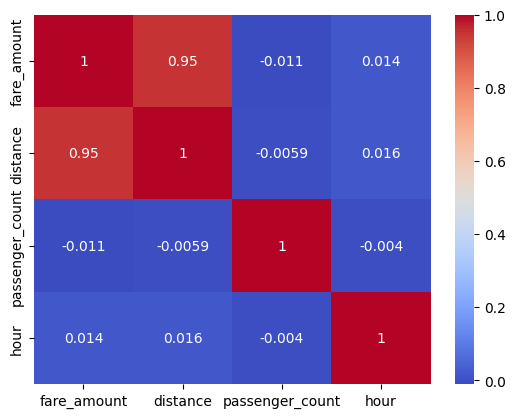

Linear  R2=0.901  RMSE=1.549
Ridge   R2=0.901  RMSE=1.549
Lasso   R2=0.901  RMSE=1.548


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# 1. Pre-process
df = pd.read_csv("data/uber.csv").dropna()
df = df[(df.pickup_latitude != 0) & (df.fare_amount > 0)]
# distance (km) from coordinates
df["distance"] = np.sqrt(((df.dropoff_latitude - df.pickup_latitude) * 111) ** 2 +
                         ((df.dropoff_longitude - df.pickup_longitude) * 84) ** 2)
df["hour"] = pd.to_datetime(df.pickup_datetime).dt.hour

# 2. Outliers (boxplot + IQR rule)
sns.boxplot(x=df.fare_amount); plt.title("Fare outliers"); plt.show()
q1, q3 = df.fare_amount.quantile([.25, .75])
df = df[df.fare_amount.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))]

# 3. Correlation
cols = ["fare_amount", "distance", "passenger_count", "hour"]
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm"); plt.show()

# 4. Models
X, y = df[["distance", "passenger_count", "hour"]], df.fare_amount
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
models = {"Linear": LinearRegression(), "Ridge": Ridge(alpha=1.0), "Lasso": Lasso(alpha=0.01)}

# 5. Evaluate & compare
for name, m in models.items():
    p = m.fit(X_train, y_train).predict(X_test)
    print(f"{name:7s} R2={r2_score(y_test, p):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, p)):.3f}")